In [2]:
import pandas as pd

df = pd.read_csv("/home/thinkpad/Documents/BrototypeStudying/paper_three/Module12/data/customer_segmentation.csv")

data = df.drop(columns="customer_id")

In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X = scaler.fit_transform(data)

Text(0.5, 1.0, 'elbow Method')

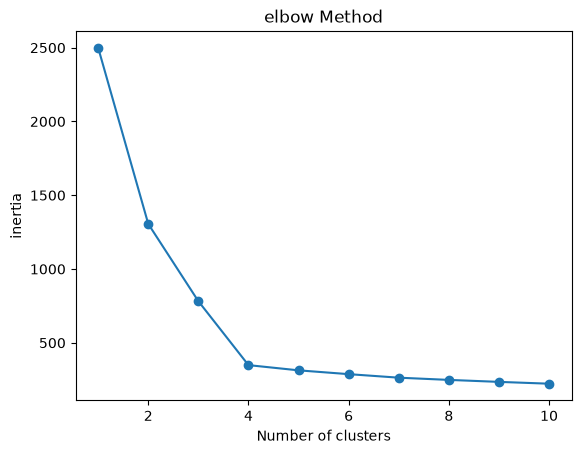

In [7]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X)
    inertia.append(model.inertia_)
    
plt.plot(range(1, 11), inertia, marker = "o")
plt.xlabel("Number of clusters")
plt.ylabel("inertia")
plt.title("elbow Method")    

In [14]:
model = KMeans(n_clusters=4, n_init=10, random_state=42)
model.fit(X)

data["cluster"] = model.labels_

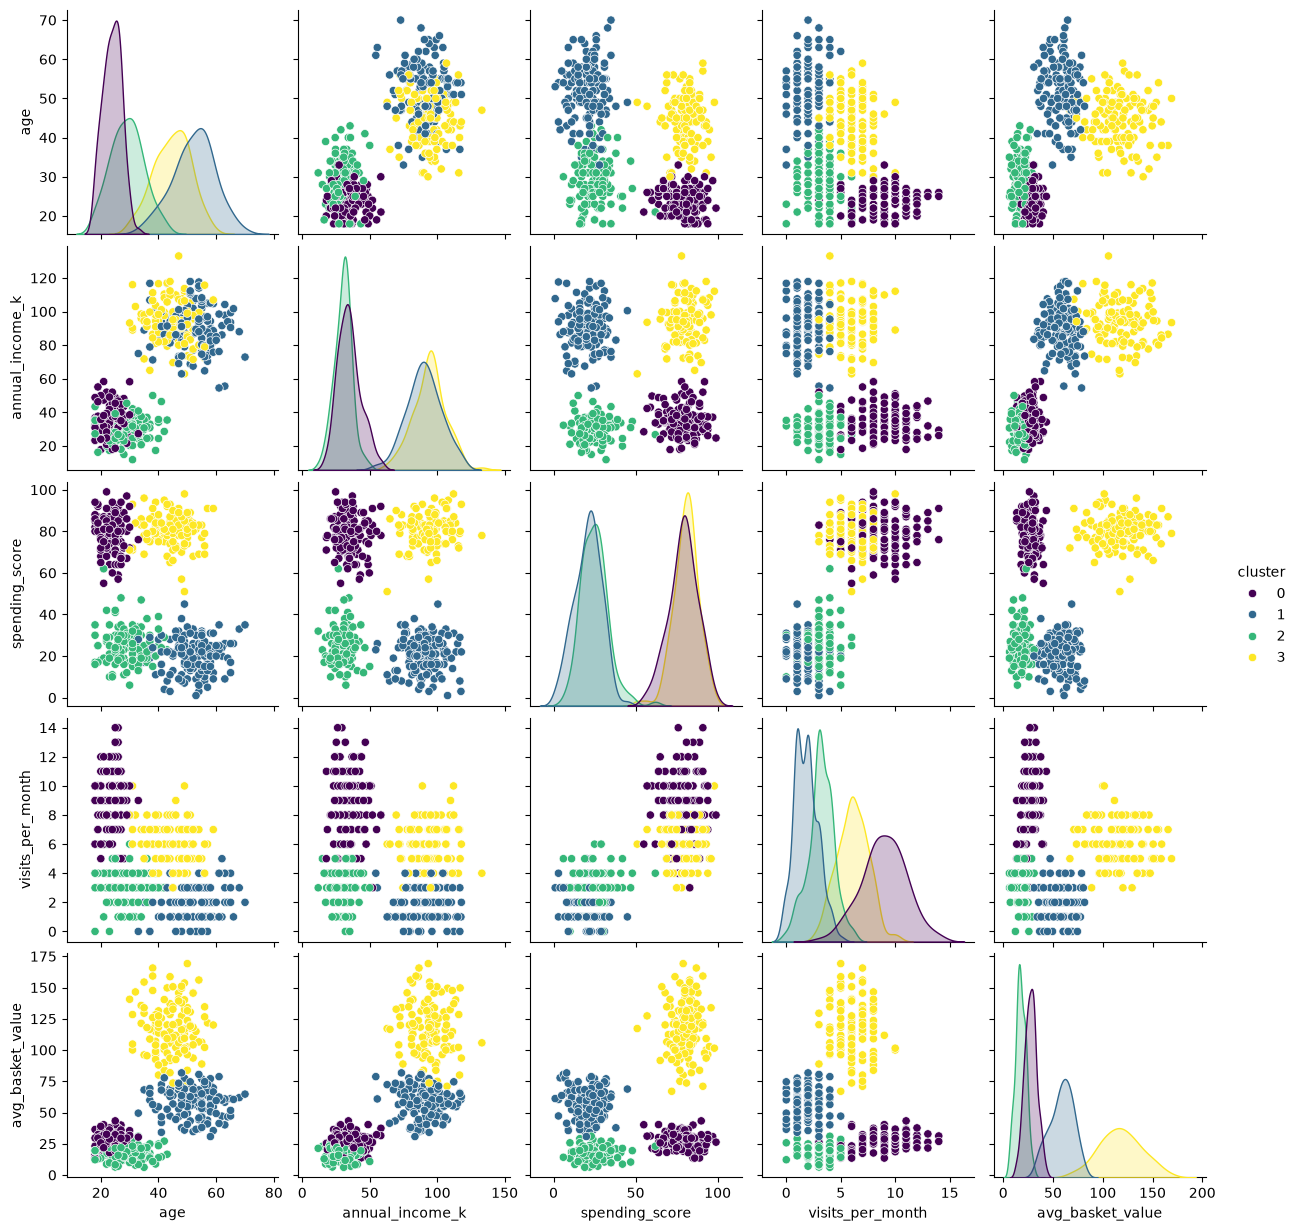

In [15]:
import seaborn as sns

sns.pairplot(data, hue="cluster", palette="viridis")

In [16]:
data.columns

Index(['age', 'annual_income_k', 'spending_score', 'visits_per_month',
       'avg_basket_value', 'cluster'],
      dtype='str')

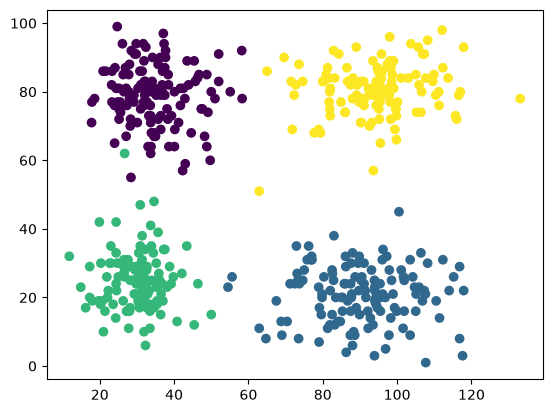

In [22]:
plt.scatter(data["annual_income_k"], data["spending_score"], c=data["cluster"])

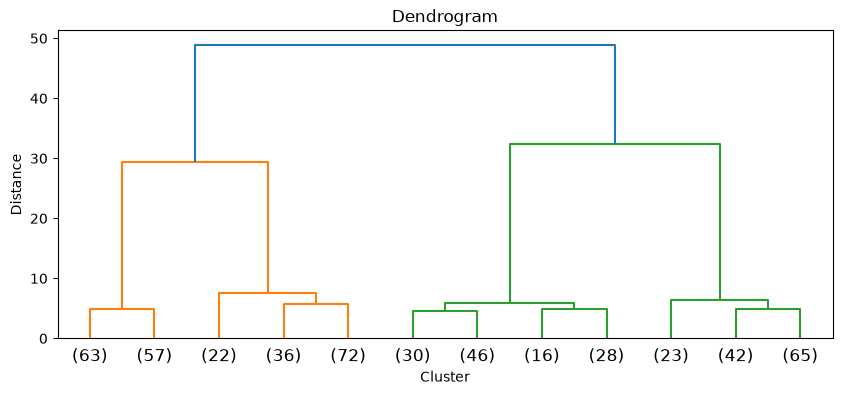

In [5]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

Z = linkage(X, method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=12)
plt.title("Dendrogram")
plt.xlabel("Cluster")
plt.ylabel("Distance")
plt.show()

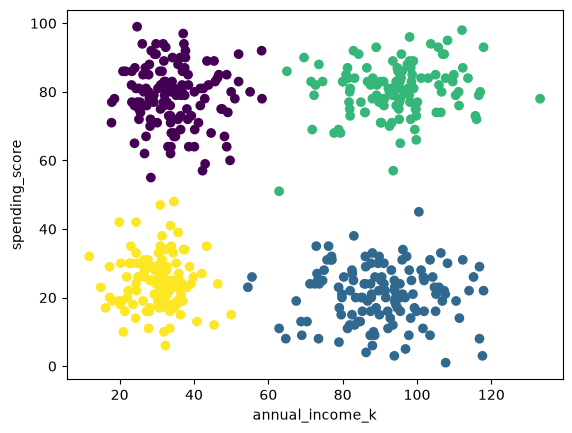

In [7]:
from sklearn.cluster import AgglomerativeClustering

model = AgglomerativeClustering(n_clusters=4, linkage="ward")
model.fit(X)

data["cluster_agg"] = model.labels_

plt.scatter(data["annual_income_k"], data["spending_score"], c=model.labels_)
plt.xlabel("annual_income_k")
plt.ylabel("spending_score")
plt.show()

In [9]:
from sklearn.metrics import silhouette_score
labels = model.labels_
print(silhouette_score(X, labels))

0.6073112039686982
